# Olist marketplace operations — analysis

Reads the dbt analysis marts in `OLIST.ANALYSIS`. Definitions (analysis window, delivery base, late, days late, minimum volume) are in `CLAUDE.md` → *Analysis definitions*.

## 6a. Delivery performance

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import snowflake.connector
from scipy import stats
from pathlib import Path

IMAGES = Path("../images"); IMAGES.mkdir(exist_ok=True)
MIN_ORDERS = 100   # minimum orders for any state or lane shown in a ranking

# Chart style (reference palette: single series = blue; ink for text; light surface)
BLUE, INK, INK2, SURFACE, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

conn = snowflake.connector.connect(connection_name="olist")
conn.cursor().execute("USE WAREHOUSE OLIST_WH")

def q(sql):
    cur = conn.cursor()
    cur.execute(sql)
    df = cur.fetch_pandas_all()
    df.columns = df.columns.str.lower()
    return df

### Delivery base

Delivered orders in the analysis window without impossible timestamps. The definitions require reporting how many orders the impossible-timestamp rule excludes.

In [2]:
excl = q("""
    SELECT COUNT_IF(is_in_analysis_window AND is_delivered_with_date)                       AS delivered_in_window,
           COUNT_IF(is_in_analysis_window AND is_delivered_with_date AND has_impossible_timestamps) AS excluded_impossible
    FROM OLIST.CORE.FCT_ORDERS""")

orders = q("""
    SELECT order_id, customer_state, seller_state, lane, is_multi_seller,
           is_late, days_late, distance_km::FLOAT AS distance_km
    FROM OLIST.ANALYSIS.MART_DELIVERY_ORDERS""")

assert len(orders) == 96_019, len(orders)
n = len(orders)
late_n = int(orders.is_late.sum())
late_rate = late_n / n
# 95% Wilson interval for the overall late rate
ci_lo, ci_hi = stats.binomtest(late_n, n).proportion_ci(method="wilson")

summary = pd.DataFrame({
    "metric": ["delivered orders in window", "excluded: impossible timestamps", "delivery base",
               "late orders", "late rate", "late rate 95% CI",
               "median days late (negative = early)", "mean days late"],
    "value": [f"{excl.delivered_in_window[0]:,}", f"{excl.excluded_impossible[0]:,}", f"{n:,}",
              f"{late_n:,}", f"{late_rate:.2%}", f"{ci_lo:.2%} – {ci_hi:.2%}",
              f"{orders.days_late.median():.0f}", f"{orders.days_late.mean():.1f}"],
})
summary

,metric,value
0,delivered orders in window,"96,203"
1,excluded: impossible timestamps,184
2,delivery base,"96,019"
3,late orders,"6,529"
4,late rate,6.80%
5,late rate 95% CI,6.64% – 6.96%
6,median days late (negative = early),-12
7,mean days late,-11.8


### Worst lanes and customer states (minimum 100 orders)

Lane = primary seller's state → customer state. Groups below `MIN_ORDERS` are not ranked.

In [3]:
perf = q("""
    SELECT dimension, group_value, order_count, late_count,
           late_rate::FLOAT AS late_rate, avg_days_late::FLOAT AS avg_days_late,
           avg_distance_km::FLOAT AS avg_distance_km
    FROM OLIST.ANALYSIS.MART_DELIVERY_PERFORMANCE""")

# Cross-check: recompute lane late rates from order-level rows; must equal the mart.
chk = orders.groupby("lane").agg(order_count=("order_id", "size"), late_count=("is_late", "sum"))
m = perf[perf.dimension == "lane"].set_index("group_value")[["order_count", "late_count"]]
assert chk.sort_index().astype(int).equals(m.sort_index().astype(int)), "mart and order-level disagree"

def ranked(dim, top):
    d = perf[(perf.dimension == dim) & (perf.order_count >= MIN_ORDERS)]
    eligible = len(d)
    total = (perf.dimension == dim).sum()
    coverage = d.order_count.sum() / n
    t = (d.sort_values(["late_rate", "order_count"], ascending=[False, False]).head(top)
           .rename(columns={"group_value": dim}).drop(columns="dimension").reset_index(drop=True))
    t.index += 1
    print(f"{dim}: {eligible} of {total} groups have >= {MIN_ORDERS} orders "
          f"(covering {coverage:.1%} of the delivery base)")
    return t.style.format({"order_count": "{:,}", "late_count": "{:,}", "late_rate": "{:.1%}",
                           "avg_days_late": "{:.1f}", "avg_distance_km": "{:,.0f}"})

ranked("lane", 10)

lane: 70 of 410 groups have >= 100 orders (covering 94.7% of the delivery base)


,lane,order_count,late_count,late_rate,avg_days_late,avg_distance_km
1,SP→AL,255,61,23.9%,-7.9,"1,903"
2,MA→SP,124,25,20.2%,-10.0,"2,332"
3,SP→MA,486,93,19.1%,-9.1,"2,178"
4,SP→PI,326,54,16.6%,-10.4,"2,015"
5,SP→SE,206,34,16.5%,-9.4,"1,724"
6,PR→BA,143,21,14.7%,-10.3,"1,768"
7,SP→RJ,"8,124","1,152",14.2%,-10.8,441
8,SP→CE,967,133,13.8%,-10.8,"2,258"
9,SP→BA,"2,302",297,12.9%,-10.7,"1,389"
10,SP→MS,475,59,12.4%,-10.1,809


In [4]:
ranked("customer_state", 5)

customer_state: 24 of 27 groups have >= 100 orders (covering 99.8% of the delivery base)


,customer_state,order_count,late_count,late_rate,avg_days_late,avg_distance_km
1,AL,396,85,21.5%,-8.6,"1,832"
2,MA,710,125,17.6%,-9.4,"2,101"
3,SE,331,51,15.4%,-9.8,"1,651"
4,PI,472,66,14.0%,-11.2,"1,955"
5,CE,"1,272",176,13.8%,-10.6,"2,188"


### Distance vs days late

Distance = haversine km between the seller and customer zip-prefix median points. Orders where either point is missing are left out of this section (count shown).

In [5]:
d = orders.dropna(subset=["distance_km"]).copy()
print(f"orders with a distance: {len(d):,} of {n:,} ({n - len(d):,} missing a zip point)")

edges = [0, 100, 250, 500, 1000, 2000, np.inf]
labels = ["0–100", "100–250", "250–500", "500–1,000", "1,000–2,000", "2,000+"]
d["distance_band"] = pd.cut(d.distance_km, bins=edges, labels=labels, right=False)

bands = (d.groupby("distance_band", observed=False)
           .agg(orders=("order_id", "size"), late_rate=("is_late", "mean"),
                median_days_late=("days_late", "median"), mean_days_late=("days_late", "mean")))

pearson = stats.pearsonr(d.distance_km, d.days_late)
spearman = stats.spearmanr(d.distance_km, d.days_late)
pb = stats.pointbiserialr(d.is_late.astype(int), d.distance_km)
fmt_p = lambda p: "< 1e-300" if p == 0 else f"= {p:.1e}"
print(f"Pearson r (distance, days late)    = {pearson.statistic:.3f}  (p {fmt_p(pearson.pvalue)})")
print(f"Spearman rho (distance, days late) = {spearman.statistic:.3f}  (p {fmt_p(spearman.pvalue)})")
print(f"Point-biserial r (distance, late)  = {pb.statistic:.3f}  (p {fmt_p(pb.pvalue)})")

bands.style.format({"orders": "{:,}", "late_rate": "{:.1%}",
                    "median_days_late": "{:.0f}", "mean_days_late": "{:.1f}"})

orders with a distance: 95,541 of 96,019 (478 missing a zip point)
Pearson r (distance, days late)    = -0.075  (p = 2.3e-119)
Spearman rho (distance, days late) = -0.180  (p < 1e-300)
Point-biserial r (distance, late)  = 0.076  (p = 8.3e-122)


,orders,late_rate,median_days_late,mean_days_late
distance_band,,,,
0–100,"17,819",4.5%,-9,-9.5
100–250,"9,386",4.9%,-12,-11.4
250–500,"27,445",6.6%,-13,-12.2
"500–1,000","25,619",7.2%,-14,-12.6
"1,000–2,000","9,686",9.5%,-14,-12.8
"2,000+","5,586",12.1%,-14,-12.6


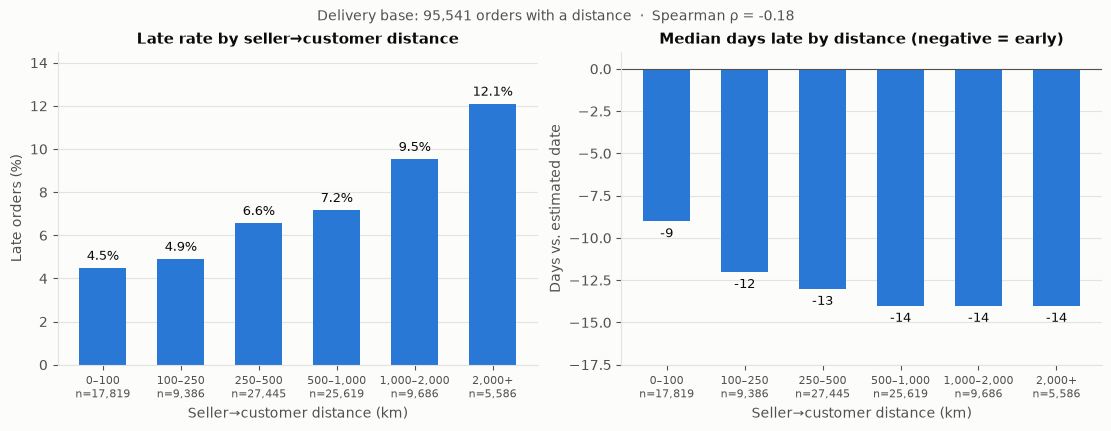

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
xt = [f"{lab}\nn={c:,}" for lab, c in zip(bands.index, bands.orders)]
x = np.arange(len(bands))

ax = axes[0]
ax.bar(x, bands.late_rate * 100, width=0.6, color=BLUE)
for xi, v in zip(x, bands.late_rate * 100):
    ax.text(xi, v + 0.25, f"{v:.1f}%", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_title("Late rate by seller→customer distance")
ax.set_ylabel("Late orders (%)")
ax.set_xticks(x, xt, fontsize=8)
ax.set_xlabel("Seller→customer distance (km)")
ax.set_ylim(0, max(bands.late_rate * 100) * 1.2)

ax = axes[1]
ax.bar(x, bands.median_days_late, width=0.6, color=BLUE)
for xi, v in zip(x, bands.median_days_late):
    ax.text(xi, v - 0.4, f"{v:.0f}", ha="center", va="top", fontsize=9, color=INK)
ax.axhline(0, color=INK2, linewidth=0.8)
ax.set_title("Median days late by distance (negative = early)")
ax.set_ylabel("Days vs. estimated date")
ax.set_xticks(x, xt, fontsize=8)
ax.set_xlabel("Seller→customer distance (km)")
ax.set_ylim(min(bands.median_days_late) * 1.25, 1)

fig.suptitle(f"Delivery base: {len(d):,} orders with a distance  ·  "
             f"Spearman ρ = {spearman.statistic:.2f}", fontsize=10, color=INK2)
fig.savefig(IMAGES / "6a_distance_vs_lateness.png", dpi=150)
plt.show()

In [7]:
try:
    conn.cursor().execute("ALTER WAREHOUSE OLIST_WH SUSPEND")  # stop credits now
except snowflake.connector.errors.ProgrammingError:
    pass  # already auto-suspended
conn.close()